# Physics-Informed Learning for Flood Reconstruction — Model Comparison

[Zaragoza O4 dataset](https://zenodo.org/records/17777387) · Segovia-Burillo et al. · [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)

## Introduction

I am from Nepal, and seeing the effects of Himalayan glacial lake outburst floods made flood research feel personal to me. After working on [rainfall prediction in Nepal](https://www.kaggle.com/code/bashcode223/rainfall-prediction-nepal-rf-ann-xgb), I wanted to explore how machine learning could help us understand the movement of floodwater.

This notebook compares interpolation, polynomial ridge regression, Random Forest, and an artificial neural network for reconstructing water-surface elevation from sparse observations. A separate simulation compares a data-only neural network with a physics-informed neural network (PINN).

The measured data comes from a laboratory experiment in Zaragoza, Spain; the PINN benchmark uses simulated shallow-water flow. These experiments are a starting point for studying methods that could later be tested with Himalayan flood data.

## 1. Imports and Configuration

Import the libraries and set the data source, random seed, sensor count, and training steps. The default configuration uses processed data and CPU training for a lightweight local run.

In [1]:
from pathlib import Path
import copy
import hashlib
import json
import random
import time

import h5py
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from scipy.interpolate import interp1d
from scipy.spatial import Delaunay, cKDTree
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures, StandardScaler

%matplotlib inline

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "reports/artifacts").is_dir()), Path.cwd())
DATA_SOURCE = "processed"  # "processed" or "raw"
PROCESSED_DIR = ROOT / "reports/artifacts"
RAW_DIR = ROOT / "data/raw/zaragoza-17777387/extracted/O4"
OUTPUT_DIR = ROOT / "outputs/kaggle_notebook"
SEED = 42
GRID_STRIDE = 8
N_SENSORS = 128
MLP_STEPS = 1500
PINN_STEPS = 1500
PHYSICS_WEIGHT = 0.01

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "grid.alpha": 0.18})
COLORS = {"Interpolation": "#607D8B", "Polynomial Ridge": "#8E6CBA",
          "Random Forest": "#D49232", "MLP": "#1768AC",
          "Data-only NN": "#1768AC", "PINN": "#00897B"}

if DATA_SOURCE not in {"raw", "processed"}:
    raise ValueError("DATA_SOURCE must be 'raw' or 'processed'")
if DATA_SOURCE == "processed" and not PROCESSED_DIR.is_dir():
    kaggle_files = list(Path("/kaggle/input").glob("**/O4_wave1.npz"))
    if not kaggle_files:
        raise FileNotFoundError("Set PROCESSED_DIR to the directory containing O4_wave1.npz and O4_wave3.npz.")
    PROCESSED_DIR = kaggle_files[0].parent

pd.DataFrame({"Parameter": ["Data source", "Seed", "Sensors", "MLP steps", "PINN steps", "Device"],
              "Value": [DATA_SOURCE, SEED, N_SENSORS, MLP_STEPS, PINN_STEPS, "CPU"]})

,Parameter,Value
0,Data source,processed
1,Seed,42
2,Sensors,128
3,MLP steps,1500
4,PINN steps,1500
5,Device,CPU


## 2. Load Raw or Processed Data

Load waves 1 and 3 from the Zaragoza O4 experiment. Processed files contain masked, spatially subsampled measurements in meters; the raw HDF5 loader performs those steps directly. The target is water-surface elevation relative to the initial bed.

In [2]:
def read_wave(wave):
    if DATA_SOURCE == "processed":
        with np.load(PROCESSED_DIR / f"O4_wave{wave}.npz", allow_pickle=False) as data:
            return {key: data[key] for key in data.files}

    with h5py.File(RAW_DIR / "offset.h5", "r") as f:
        x = f["gX"][::GRID_STRIDE, ::GRID_STRIDE].astype(float)
        y = f["gY"][::GRID_STRIDE, ::GRID_STRIDE].astype(float)
        mask = f["mask"][::GRID_STRIDE, ::GRID_STRIDE] != 0

    frames = []
    for path in (RAW_DIR / f"water{wave}_h5").glob("*.h5"):
        with h5py.File(path, "r") as f:
            gx = f["gX"][::GRID_STRIDE, ::GRID_STRIDE]
            gy = f["gY"][::GRID_STRIDE, ::GRID_STRIDE]
            np.testing.assert_allclose(gx, x, atol=1e-4)
            np.testing.assert_allclose(gy, y, atol=1e-4)
            frames.append((float(f.attrs["time_stamp[s]"]),
                           f["wse[mm]"][::GRID_STRIDE, ::GRID_STRIDE].astype(float)))
    if not frames:
        raise FileNotFoundError(f"Missing raw water{wave}_h5 files in RAW_DIR")
    frames.sort(key=lambda item: item[0])
    water = np.stack([item[1] for item in frames])
    valid = mask & np.isfinite(x) & np.isfinite(y) & np.all(np.isfinite(water), axis=0)
    return {"xy": np.column_stack([x[valid], y[valid]]) / 1000,
            "time_s": np.array([item[0] for item in frames]),
            "wse_m": water[:, valid] / 1000}

manifest_path = PROCESSED_DIR / "manifest.json"
if DATA_SOURCE == "processed" and manifest_path.exists():
    manifest = json.loads(manifest_path.read_text())
    for name in ["O4_wave1.npz", "O4_wave3.npz"]:
        assert hashlib.sha256((PROCESSED_DIR / name).read_bytes()).hexdigest() == manifest[name]["sha256"]

wave1 = read_wave(1)
wave3 = read_wave(3)
pd.DataFrame([
    {"Wave": 1, "Frames": len(wave1["time_s"]), "Locations": len(wave1["xy"]),
     "WSE array": str(wave1["wse_m"].shape)},
    {"Wave": 3, "Frames": len(wave3["time_s"]), "Locations": len(wave3["xy"]),
     "WSE array": str(wave3["wse_m"].shape)},
])

,Wave,Frames,Locations,WSE array
0,1,120,1279,"(120, 1279)"
1,3,120,1277,"(120, 1277)"


## 3. Preprocessing

Sort timestamps, remove invalid or duplicate spatial locations, and check array shapes. Flatten wave 1 into a table with spatial coordinates and time as features, and water-surface elevation as the regression target.

In [3]:
def clean_wave(data):
    xy = np.asarray(data["xy"], dtype=np.float64)
    times = np.asarray(data["time_s"], dtype=np.float64)
    water = np.asarray(data["wse_m"], dtype=np.float64)
    assert xy.ndim == 2 and xy.shape[1] == 2
    assert water.shape == (len(times), len(xy))
    assert np.isfinite(times).all()

    order = np.argsort(times)
    times, water = times[order], water[order]
    if np.any(np.diff(times) <= 0):
        raise ValueError("Duplicate measurement timestamps")
    valid = np.isfinite(xy).all(axis=1) & np.isfinite(water).all(axis=0)
    xy, water = xy[valid], water[:, valid]
    _, first = np.unique(xy, axis=0, return_index=True)
    first = np.sort(first)
    return {"xy": xy[first], "time_s": times, "wse_m": water[:, first]}

wave1, wave3 = clean_wave(wave1), clean_wave(wave3)
xy, times, water = wave1["xy"], wave1["time_s"], wave1["wse_m"]
df = pd.DataFrame({
    "frame_id": np.repeat(np.arange(len(times)), len(xy)),
    "point_id": np.tile(np.arange(len(xy)), len(times)),
    "x_m": np.tile(xy[:, 0], len(times)),
    "y_m": np.tile(xy[:, 1], len(times)),
    "time_s": np.repeat(times, len(xy)),
    "wse_m": water.ravel(),
})
df.head()

,frame_id,point_id,x_m,y_m,time_s,wse_m
0,0,0,1.1976,0.0128,0.800541,0.002347
1,0,1,1.2088,0.0128,0.800541,-0.001014
2,0,2,1.2200,0.0128,0.800541,-0.000078
3,0,3,1.2312,0.0128,0.800541,0.000744
4,0,4,1.2424,0.0128,0.800541,-0.001243


In [4]:
df.info()
display(df.isna().sum().rename("Missing values").to_frame())
df[["x_m", "y_m", "time_s", "wse_m"]].describe().T

<class 'pandas.DataFrame'>
RangeIndex: 153480 entries, 0 to 153479
Data columns (total 6 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   frame_id  153480 non-null  int64  
 1   point_id  153480 non-null  int64  
 2   x_m       153480 non-null  float64
 3   y_m       153480 non-null  float64
 4   time_s    153480 non-null  float64
 5   wse_m     153480 non-null  float64
dtypes: float64(4), int64(2)
memory usage: 7.0 MB


,Missing values
frame_id,0
point_id,0
x_m,0
y_m,0
time_s,0
wse_m,0


,count,mean,std,min,25%,50%,75%,max
x_m,153480.0,1.604478,0.229485,1.197600,1.399200,1.600800,1.802400,2.004000
y_m,153480.0,0.108092,0.059534,0.012800,0.057600,0.102400,0.158400,0.225600
time_s,153480.0,2.807603,1.169754,0.800541,1.793535,2.820341,3.812938,4.804995
wse_m,153480.0,0.023891,0.017840,-0.009708,0.001913,0.028295,0.038749,0.084118


## 4. Exploratory Data Analysis

Inspect the target distribution, changes over time, and spatial snapshots of the flood wave. These plots show the range of elevations and how the water surface changes across the measured area.

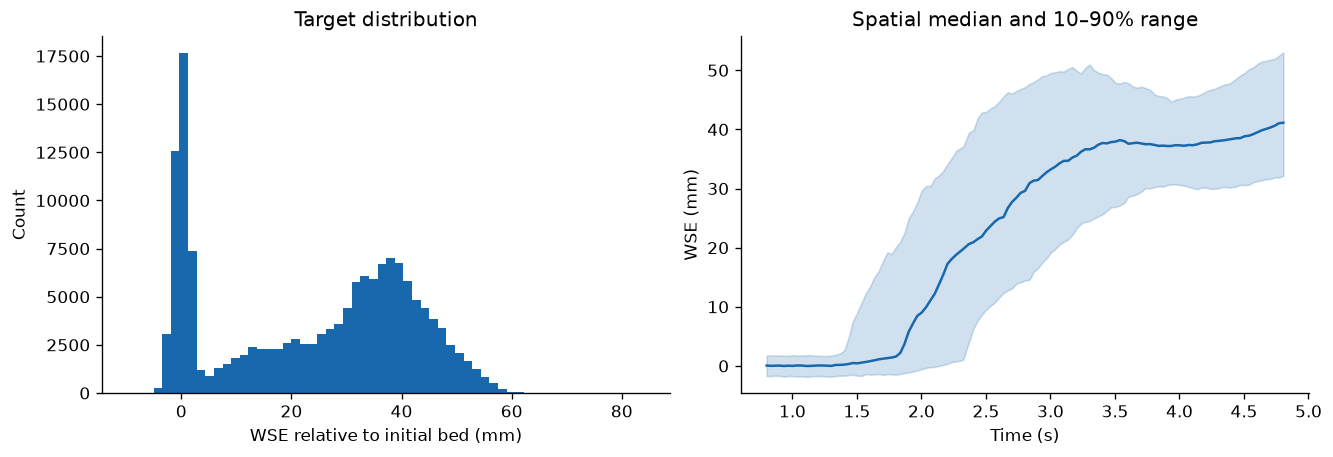

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
axes[0].hist(water.ravel() * 1000, bins=60, color=COLORS["MLP"])
axes[0].set(xlabel="WSE relative to initial bed (mm)", ylabel="Count", title="Target distribution")
quantiles = np.percentile(water * 1000, [10, 50, 90], axis=1)
axes[1].fill_between(times, quantiles[0], quantiles[2], alpha=0.2, color=COLORS["MLP"])
axes[1].plot(times, quantiles[1], color=COLORS["MLP"])
axes[1].set(xlabel="Time (s)", ylabel="WSE (mm)", title="Spatial median and 10–90% range")
plt.show()

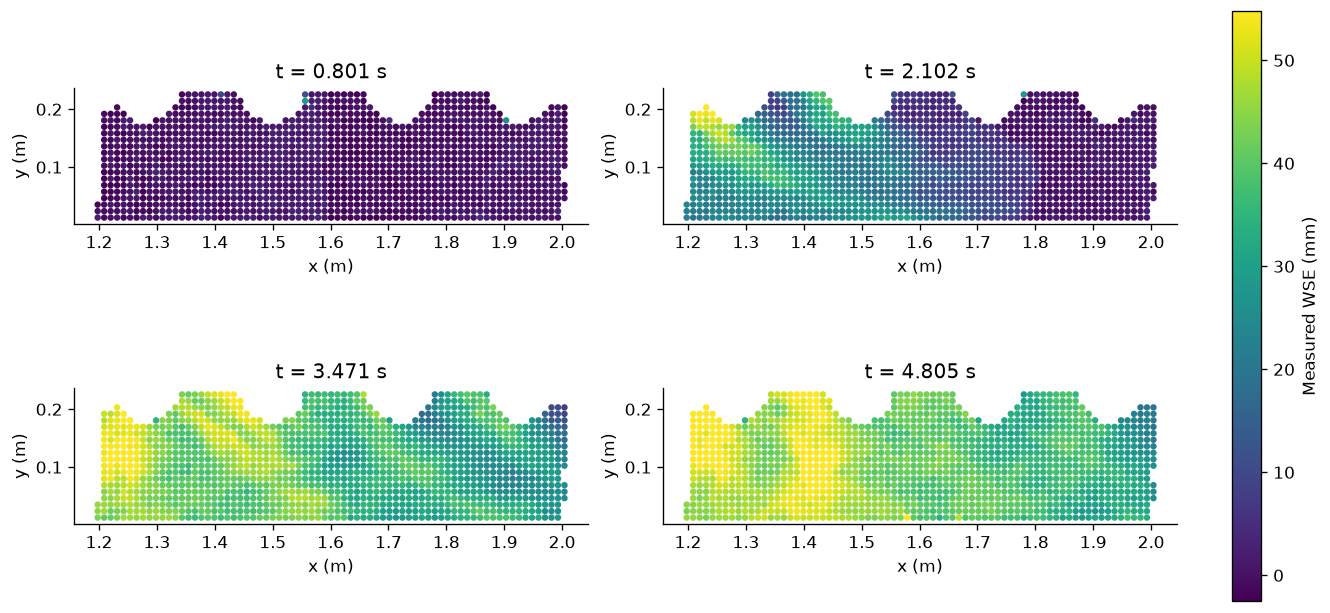

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5), layout="constrained")
limits = np.percentile(water * 1000, [1, 99])
for ax, frame in zip(axes.flat, np.linspace(0, len(times) - 1, 4, dtype=int)):
    image = ax.scatter(xy[:, 0], xy[:, 1], c=water[frame] * 1000, s=8,
                       cmap="viridis", vmin=limits[0], vmax=limits[1])
    ax.set(xlabel="x (m)", ylabel="y (m)", title=f"t = {times[frame]:.3f} s", aspect="equal")
fig.colorbar(image, ax=axes.ravel().tolist(), label="Measured WSE (mm)")
plt.show()

## 5. Train / Validation / Test Split

Train on a subset of locations treated as virtual sensors. Validation and test sets use other locations at separate held-out frames, measuring reconstruction within the same wave. Validation selects the model; test observations stay out of training and selection.

In [7]:
if not 3 <= N_SENSORS < len(xy):
    raise ValueError("N_SENSORS must be between 3 and the spatial point count minus one")
frame_ids = np.arange(len(times))
interior = (frame_ids > 0) & (frame_ids < len(times) - 1)
val_frames = frame_ids[interior & (frame_ids % 5 == 2)]
test_frames = frame_ids[interior & (frame_ids % 5 == 4)]
train_frames = np.setdiff1d(frame_ids, np.r_[val_frames, test_frames])
sensor_ids = np.sort(np.random.default_rng(SEED).choice(len(xy), N_SENSORS, replace=False))
heldout_ids = np.setdiff1d(np.arange(len(xy)), sensor_ids)

train_rows = df.frame_id.isin(train_frames) & df.point_id.isin(sensor_ids)
val_rows = df.frame_id.isin(val_frames) & df.point_id.isin(heldout_ids)
test_rows = df.frame_id.isin(test_frames) & df.point_id.isin(heldout_ids)
assert not (train_rows & val_rows).any() and not (train_rows & test_rows).any()
assert not (val_rows & test_rows).any()

FEATURES = ["x_m", "y_m", "time_s"]
X_train, y_train = df.loc[train_rows, FEATURES].to_numpy(), df.loc[train_rows, "wse_m"].to_numpy()
X_val, y_val = df.loc[val_rows, FEATURES].to_numpy(), df.loc[val_rows, "wse_m"].to_numpy()
X_test, y_test = df.loc[test_rows, FEATURES].to_numpy(), df.loc[test_rows, "wse_m"].to_numpy()

pd.DataFrame({"Split": ["Train", "Validation", "Test"],
              "Frames": [len(train_frames), len(val_frames), len(test_frames)],
              "Locations": [len(sensor_ids), len(heldout_ids), len(heldout_ids)],
              "Samples": [len(y_train), len(y_val), len(y_test)]})

,Split,Frames,Locations,Samples
0,Train,73,128,9344
1,Validation,24,1151,27624
2,Test,23,1151,26473


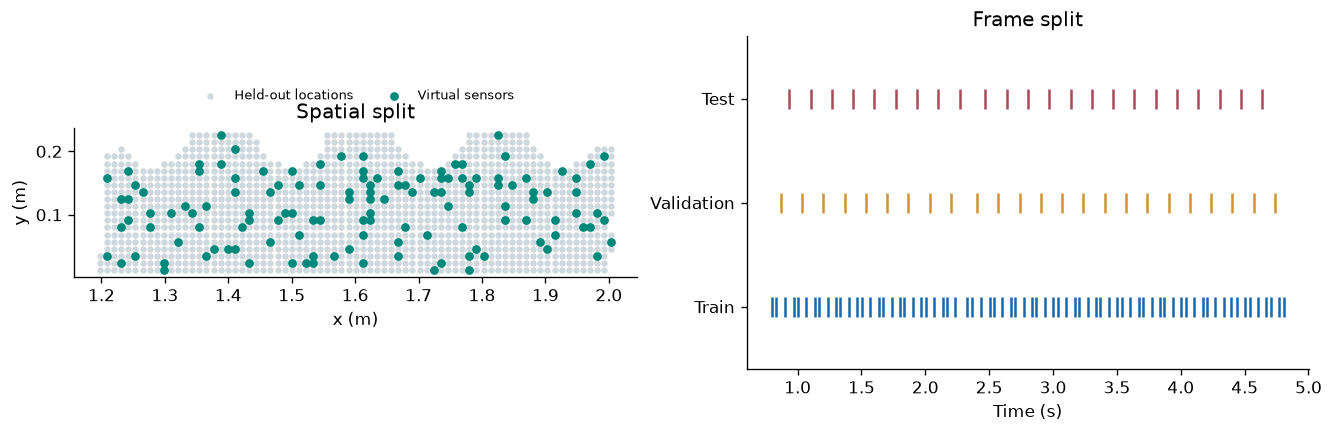

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].scatter(xy[heldout_ids, 0], xy[heldout_ids, 1], c="#CFD8DC", s=8, label="Held-out locations")
axes[0].scatter(xy[sensor_ids, 0], xy[sensor_ids, 1], c=COLORS["PINN"], s=18, label="Virtual sensors")
axes[0].set(xlabel="x (m)", ylabel="y (m)", aspect="equal", title="Spatial split")
axes[0].legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.35), ncol=2)
for row, (frames, label, color) in enumerate([
    (train_frames, "Train", COLORS["MLP"]), (val_frames, "Validation", "#D49232"),
    (test_frames, "Test", "#AA4A59"),
]):
    axes[1].scatter(times[frames], np.full(len(frames), row), marker="|", s=130, c=color)
axes[1].set(yticks=[0, 1, 2], yticklabels=["Train", "Validation", "Test"],
            xlabel="Time (s)", title="Frame split", ylim=(-0.6, 2.6))
plt.show()

## 6. Feature Scaling

Scale the neural network's coordinate and time inputs to the range −1 to 1, and standardize its target. Fit all scaling statistics on training data only, then convert predictions back to physical units for evaluation.

In [9]:
feature_scaler = MinMaxScaler(feature_range=(-1, 1)).fit(X_train)
target_mean, target_std = float(y_train.mean()), max(float(y_train.std()), 1e-6)
X_train_tensor = torch.tensor(feature_scaler.transform(X_train), dtype=torch.float32)
y_train_tensor = torch.tensor((y_train - target_mean) / target_std, dtype=torch.float32).reshape(-1, 1)
pd.DataFrame({"Feature": FEATURES, "Train minimum": feature_scaler.data_min_,
              "Train maximum": feature_scaler.data_max_})

,Feature,Train minimum,Train maximum
0,x_m,1.208800,2.004000
1,y_m,0.012800,0.225600
2,time_s,0.800541,4.804995


## 7. Model Definitions

Compare four approaches: interpolation connects nearby sensor observations; polynomial ridge regression fits a regularized smooth surface; Random Forest averages decision trees; and the MLP learns nonlinear relationships between location, time, and elevation. All use the same training observations.

In [10]:
regressors = {
    "Polynomial Ridge": make_pipeline(StandardScaler(), PolynomialFeatures(degree=3, include_bias=False),
                                      Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=128, max_depth=16, min_samples_leaf=2,
                                           random_state=SEED, n_jobs=2),
}

class CoordinateMLP(nn.Module):
    def __init__(self, inputs=3, outputs=1, width=64):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(inputs, width), nn.Tanh(), nn.Linear(width, width), nn.Tanh(),
            nn.Linear(width, width), nn.Tanh(), nn.Linear(width, outputs),
        )

    def forward(self, x):
        return self.network(x)

torch.manual_seed(SEED)
mlp = CoordinateMLP()
mlp

CoordinateMLP(
  (network): Sequential(
    (0): Linear(in_features=3, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [11]:
def interpolation_field(query_xy, query_times):
    sensor_xy = xy[sensor_ids]
    values = water[np.ix_(train_frames, sensor_ids)]
    triangulation = Delaunay(sensor_xy)
    simplex = triangulation.find_simplex(query_xy)
    inside = simplex >= 0
    result = np.empty((len(train_frames), len(query_xy)))
    transform = triangulation.transform[simplex[inside]]
    barycentric = np.einsum("nij,nj->ni", transform[:, :2], query_xy[inside] - transform[:, 2])
    weights = np.column_stack([barycentric, 1 - barycentric.sum(axis=1)])
    vertices = triangulation.simplices[simplex[inside]]
    result[:, inside] = np.einsum("tnv,nv->tn", values[:, vertices], weights)
    if (~inside).any():
        nearest = cKDTree(sensor_xy).query(query_xy[~inside])[1]
        result[:, ~inside] = values[:, nearest]
    return interp1d(times[train_frames], result, axis=0)(query_times)

def predict_mlp(features):
    mlp.eval()
    predictions = []
    with torch.no_grad():
        for chunk in np.array_split(features, max(1, int(np.ceil(len(features) / 8192)))):
            x = torch.tensor(feature_scaler.transform(chunk), dtype=torch.float32)
            predictions.append(mlp(x).numpy().ravel() * target_std + target_mean)
    return np.concatenate(predictions)

def regression_scores(truth, prediction):
    truth_mm, prediction_mm = truth * 1000, prediction * 1000
    return {"RMSE (mm)": root_mean_squared_error(truth_mm, prediction_mm),
            "MAE (mm)": mean_absolute_error(truth_mm, prediction_mm),
            "R²": r2_score(truth_mm, prediction_mm),
            "95th abs. error (mm)": np.percentile(np.abs(prediction_mm - truth_mm), 95)}

## 8. Model Training

Fit the regression models and train the MLP with Adam. Restore the MLP checkpoint with the lowest validation RMSE. Training and validation curves help show whether learning is improving or starting to overfit.

In [12]:
fit_times = {}
for name, model in regressors.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_times[name] = time.perf_counter() - start
fit_times

{'Polynomial Ridge': 0.0018111660028807819,
 'Random Forest': 0.34474258302361704}

In [13]:
optimizer = torch.optim.Adam(mlp.parameters(), lr=0.001)
best_val, best_state, best_step = float("inf"), None, 0
mlp_history = []
start = time.perf_counter()

for step in range(1, MLP_STEPS + 1):
    mlp.train()
    batch = torch.randint(len(X_train_tensor), (min(512, len(X_train_tensor)),))
    optimizer.zero_grad()
    loss = nn.functional.mse_loss(mlp(X_train_tensor[batch]), y_train_tensor[batch])
    loss.backward()
    optimizer.step()
    if step % 100 == 0 or step == MLP_STEPS:
        val_rmse = root_mean_squared_error(y_val * 1000, predict_mlp(X_val) * 1000)
        if val_rmse < best_val:
            best_val, best_state, best_step = val_rmse, copy.deepcopy(mlp.state_dict()), step
        mlp_history.append({"Step": step, "Training MSE (normalized)": loss.item(),
                            "Validation RMSE (mm)": val_rmse})

mlp.load_state_dict(best_state)
fit_times["MLP"] = time.perf_counter() - start
history_df = pd.DataFrame(mlp_history)
history_df.tail()

,Step,Training MSE (normalized),Validation RMSE (mm)
10,1100,0.055602,4.953325
11,1200,0.053232,4.954492
12,1300,0.052355,4.903391
13,1400,0.049389,4.844742
14,1500,0.045434,4.745770


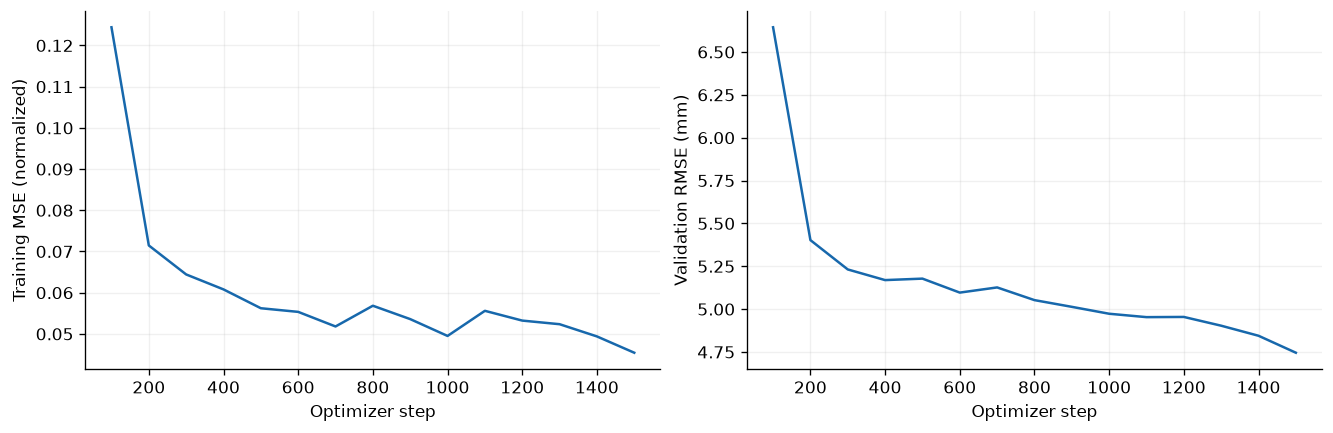

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for ax, column in zip(axes, ["Training MSE (normalized)", "Validation RMSE (mm)"]):
    ax.plot(history_df.Step, history_df[column], c=COLORS["MLP"])
    ax.set(xlabel="Optimizer step", ylabel=column)
    ax.grid()
plt.show()

## 9. Model Evaluation

Compare all models on the same held-out observations using RMSE, MAE, R², and the 95th-percentile absolute error. Lower errors and higher R² indicate better reconstruction. Error plots and spatial maps show where predictions differ from measurements; validation RMSE determines the selected model.

In [15]:
val_predictions = {name: model.predict(X_val) for name, model in regressors.items()}
test_predictions = {name: model.predict(X_test) for name, model in regressors.items()}
val_predictions["MLP"], test_predictions["MLP"] = predict_mlp(X_val), predict_mlp(X_test)
val_predictions["Interpolation"] = interpolation_field(xy[heldout_ids], times[val_frames]).ravel()
test_predictions["Interpolation"] = interpolation_field(xy[heldout_ids], times[test_frames]).ravel()

validation_results = pd.DataFrame([
    {"Model": name, **regression_scores(y_val, prediction)}
    for name, prediction in val_predictions.items()
]).sort_values("RMSE (mm)").reset_index(drop=True)
test_results = pd.DataFrame([
    {"Model": name, **regression_scores(y_test, prediction)}
    for name, prediction in test_predictions.items()
]).sort_values("RMSE (mm)").reset_index(drop=True)

display(validation_results.round(4))
display(test_results.round(4))
selected_model = validation_results.iloc[0]["Model"]
print("Selected by validation RMSE:", selected_model)

,Model,RMSE (mm),MAE (mm),R²,95th abs. error (mm)
0,Interpolation,3.5009,2.0336,0.9615,6.2213
1,Random Forest,3.7366,2.3014,0.9561,6.6570
2,MLP,4.7458,3.2185,0.9292,9.3654
3,Polynomial Ridge,6.0368,4.5100,0.8855,11.8648


,Model,RMSE (mm),MAE (mm),R²,95th abs. error (mm)
0,Interpolation,3.4422,2.0423,0.9621,6.1742
1,Random Forest,3.8051,2.3264,0.9537,6.7896
2,MLP,4.7347,3.2479,0.9284,9.1677
3,Polynomial Ridge,5.9916,4.4836,0.8853,11.6905


Selected by validation RMSE: Interpolation


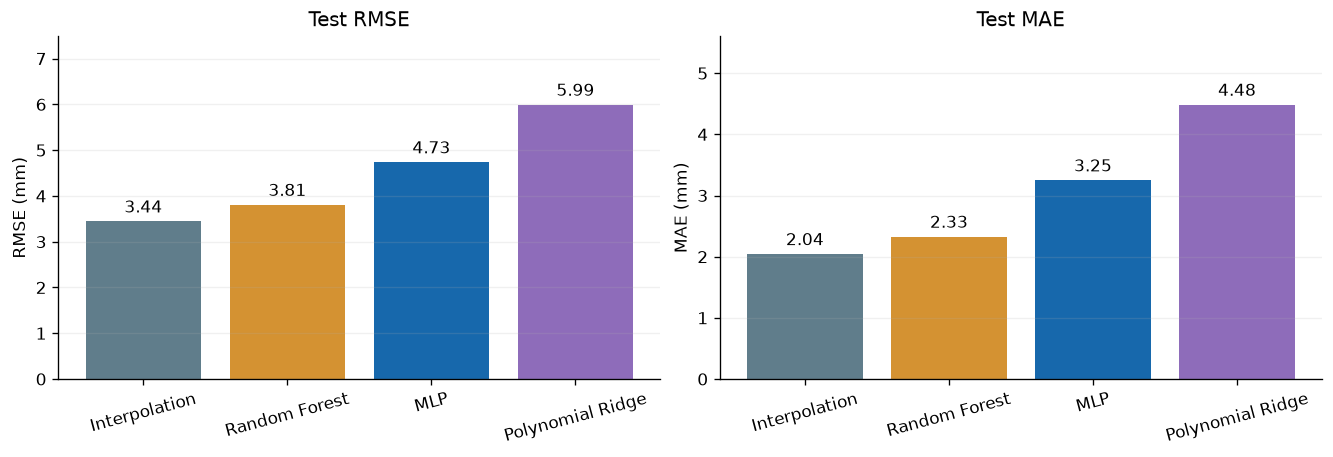

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), layout="constrained")
for ax, metric in zip(axes, ["RMSE (mm)", "MAE (mm)"]):
    bars = ax.bar(test_results.Model, test_results[metric],
                  color=[COLORS[name] for name in test_results.Model])
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set(ylabel=metric, title=f"Test {metric.split(' ')[0]}", ylim=(0, test_results[metric].max() * 1.25))
    ax.tick_params(axis="x", labelrotation=15)
    ax.grid(axis="y")
plt.show()

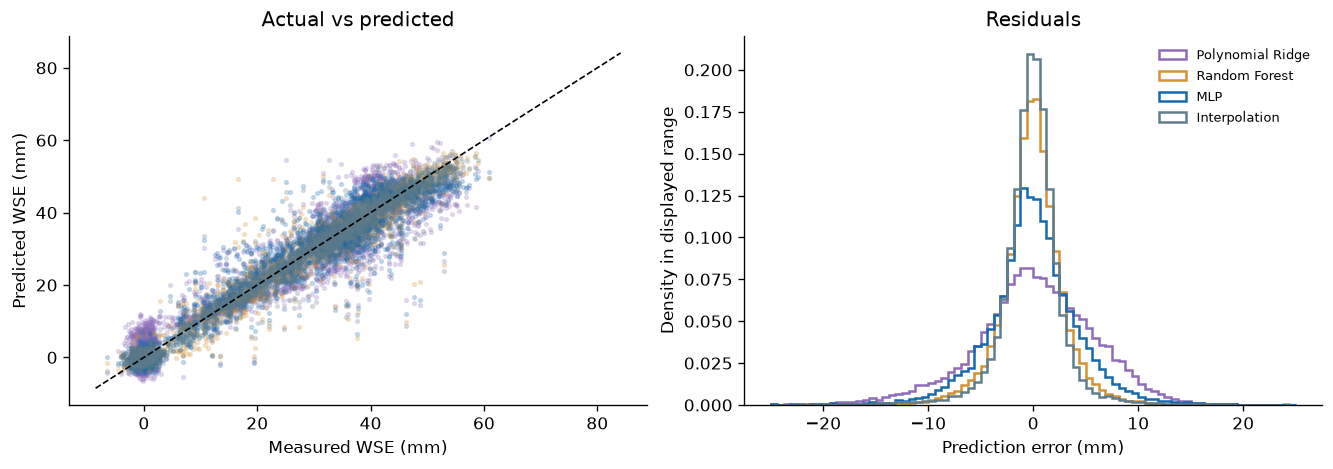

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
sample = np.random.default_rng(SEED).choice(len(y_test), min(3000, len(y_test)), replace=False)
for name, prediction in test_predictions.items():
    axes[0].scatter(y_test[sample] * 1000, prediction[sample] * 1000,
                    s=5, alpha=0.2, color=COLORS[name], label=name)
    residual = (prediction - y_test) * 1000
    axes[1].hist(residual, bins=np.linspace(-25, 25, 81), histtype="step",
                 density=True, lw=1.5, color=COLORS[name], label=name)
limits = [y_test.min() * 1000, y_test.max() * 1000]
axes[0].plot(limits, limits, c="black", ls="--", lw=1)
axes[0].set(xlabel="Measured WSE (mm)", ylabel="Predicted WSE (mm)", title="Actual vs predicted")
axes[1].set(xlabel="Prediction error (mm)", ylabel="Density in displayed range", title="Residuals")
axes[1].legend(fontsize=8, frameon=False)
plt.show()

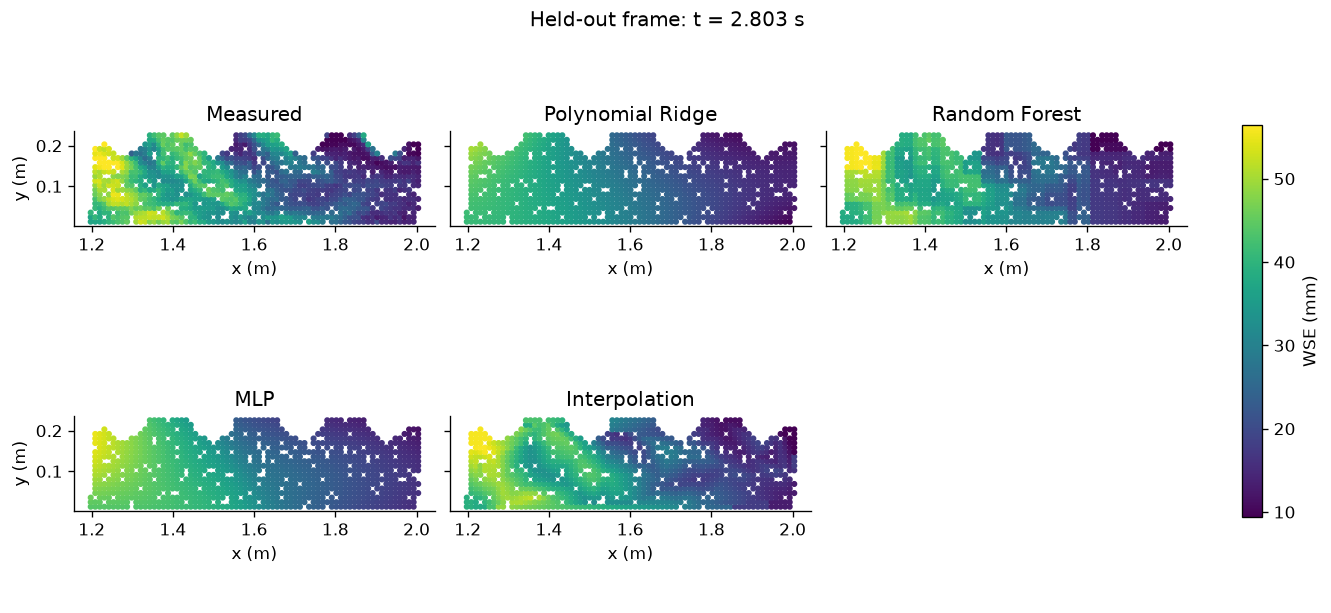

In [18]:
frame = len(test_frames) // 2
query_xy = xy[heldout_ids]
fig, axes = plt.subplots(2, 3, figsize=(11, 5), layout="constrained", sharey=True)
fields = {"Measured": y_test.reshape(len(test_frames), -1)[frame],
          **{name: value.reshape(len(test_frames), -1)[frame] for name, value in test_predictions.items()}}
limits = np.percentile(fields["Measured"] * 1000, [1, 99])
used_axes = list(axes.flat)[:len(fields)]
for ax, (name, field) in zip(used_axes, fields.items()):
    image = ax.scatter(query_xy[:, 0], query_xy[:, 1], c=field * 1000, s=7,
                       cmap="viridis", vmin=limits[0], vmax=limits[1])
    ax.set(title=name, xlabel="x (m)", aspect="equal")
axes[0, 0].set_ylabel("y (m)")
axes[1, 0].set_ylabel("y (m)")
axes[1, 2].axis("off")
fig.colorbar(image, ax=used_axes, label="WSE (mm)", shrink=0.7)
fig.suptitle(f"Held-out frame: t = {times[test_frames[frame]]:.3f} s")
plt.show()

## 10. Frozen Model Evaluation — Wave 3

Apply the wave 1 models to wave 3 without retraining, using shared spatial locations and overlapping times. This checks transfer to another wave in the same experimental geometry; the models receive no wave 3 fitting observations.

In [19]:
distance, matched_ids = cKDTree(xy).query(wave3["xy"])
common = distance <= 1e-7
time_mask = (wave3["time_s"] >= times[train_frames].min()) & (wave3["time_s"] <= times[train_frames].max())
transfer_xy, transfer_times = wave3["xy"][common], wave3["time_s"][time_mask]
X_transfer = np.column_stack([np.tile(transfer_xy, (len(transfer_times), 1)),
                              np.repeat(transfer_times, len(transfer_xy))])
y_transfer = wave3["wse_m"][time_mask][:, common].ravel()
transfer_predictions = {name: model.predict(X_transfer) for name, model in regressors.items()}
transfer_predictions["MLP"] = predict_mlp(X_transfer)
transfer_predictions["Interpolation"] = interpolation_field(transfer_xy, transfer_times).ravel()
transfer_results = pd.DataFrame([
    {"Model": name, **regression_scores(y_transfer, prediction)}
    for name, prediction in transfer_predictions.items()
]).sort_values("RMSE (mm)").reset_index(drop=True)
display(transfer_results.round(4))
print("Wave 3 fitting observations: 0")

,Model,RMSE (mm),MAE (mm),R²,95th abs. error (mm)
0,MLP,6.7156,4.9693,0.8659,13.3345
1,Interpolation,6.7990,5.0369,0.8626,13.3961
2,Random Forest,6.8605,5.0848,0.8601,13.6147
3,Polynomial Ridge,7.0080,5.2041,0.8540,13.8836


Wave 3 fitting observations: 0


## 11. Simulated Shallow-Water Data — PINN Benchmark

Generate a one-dimensional flood-wave reference with a numerical shallow-water solver on a flat, fixed bed. Check positive depth, mass balance, and grid refinement before creating sparse training observations. Depth h and discharge per unit width q are dimensionless; this is simulated data.

In [20]:
def initial_height(x):
    """Smoothed wet-bed release: h_L=1, h_R=0.1; not a real disaster measurement."""
    if isinstance(x, torch.Tensor):
        return 0.1 + 0.9 * 0.5 * (1 - torch.tanh((x - 0.45) / 0.02))
    return 0.1 + 0.9 * 0.5 * (1 - np.tanh((x - 0.45) / 0.02))

def rusanov_flux(left: np.ndarray, right: np.ndarray) -> np.ndarray:
    """Conservative local Lax-Friedrichs flux for state [h,q], g*=1."""
    def flux(state):
        h, q = state[:, 0], state[:, 1]
        return np.column_stack([q, q * q / h + 0.5 * h * h])
    speed = np.maximum(np.abs(left[:, 1] / left[:, 0]) + np.sqrt(left[:, 0]),
                       np.abs(right[:, 1] / right[:, 0]) + np.sqrt(right[:, 0]))
    return 0.5 * (flux(left) + flux(right)) - 0.5 * speed[:, None] * (right - left)

def solve_reference(cells: int = 128, frames: int = 41, final_time: float = 0.35) -> dict:
    if cells < 8 or frames < 3 or final_time <= 0:
        raise ValueError("Need at least 8 cells, 3 frames, and positive duration")
    dx = 1 / cells
    x = (np.arange(cells) + 0.5) * dx
    state = np.column_stack([initial_height(x), np.zeros(cells)])
    initial_mass = float(state[:, 0].sum() * dx)
    times = np.linspace(0, final_time, frames)
    history = [state.copy()]
    time_s, net_mass_inflow, steps = 0.0, 0.0, 0
    for target in times[1:]:
        while time_s < target - 1e-14:
            speed = np.max(np.abs(state[:, 1] / state[:, 0]) + np.sqrt(state[:, 0]))
            dt = min(0.4 * dx / speed, target - time_s)
            # Transmissive ghost cells; boundary influx is included in mass diagnostics.
            padded = np.vstack([state[0], state, state[-1]])
            interface_flux = rusanov_flux(padded[:-1], padded[1:])
            state = state - dt / dx * np.diff(interface_flux, axis=0)
            if not np.all(np.isfinite(state)) or np.any(state[:, 0] <= 0):
                raise FloatingPointError("Reference solver lost positive finite wet-bed height")
            net_mass_inflow += dt * (interface_flux[0, 0] - interface_flux[-1, 0])
            time_s += dt
            steps += 1
        history.append(state.copy())
    solution = np.stack(history)
    return {"x": x, "time": times, "state": solution,
            "diagnostics": {"cells": cells, "frames": frames, "steps": steps, "cfl": 0.4,
                            "min_height": float(solution[:, :, 0].min()),
                            "mass_balance_error": float(state[:, 0].sum() * dx - initial_mass - net_mass_inflow)}}

In [21]:
reference = solve_reference(cells=128, frames=41, final_time=0.35)
refined = solve_reference(cells=256, frames=41, final_time=0.35)
sx, st, state = reference["x"], reference["time"], reference["state"]
reference_delta = np.interp(sx, refined["x"], refined["state"][-1, :, 0]) - state[-1, :, 0]
pd.DataFrame([
    {"Check": "Minimum depth", "Value": state[:, :, 0].min()},
    {"Check": "Mass-balance error", "Value": reference["diagnostics"]["mass_balance_error"]},
    {"Check": "128 → 256 cell final-height RMSE", "Value": np.sqrt(np.mean(reference_delta**2))},
])

,Check,Value
0,Minimum depth,1.000000e-01
1,Mass-balance error,-1.774026e-17
2,128 → 256 cell final-height RMSE,8.409164e-03


In [22]:
synthetic_sensor_ids = np.linspace(6, len(sx) - 7, 12, dtype=int)
synthetic_heldout = np.setdiff1d(np.arange(len(sx)), synthetic_sensor_ids)
ids = np.arange(len(st))
interior = (ids > 0) & (ids < len(st) - 1)
sval = ids[interior & (ids % 5 == 2)]
stest = ids[interior & (ids % 5 == 4)]
strain = np.setdiff1d(ids, np.r_[sval, stest])

def xt_coordinates(xs, ts):
    return torch.tensor(np.column_stack([np.tile(xs, len(ts)), np.repeat(ts, len(xs))]), dtype=torch.float32)

sx_train = xt_coordinates(sx[synthetic_sensor_ids], st[strain])
sh_train = torch.tensor(state[np.ix_(strain, synthetic_sensor_ids)][:, :, 0].reshape(-1, 1), dtype=torch.float32)
initial_x = xt_coordinates(sx, [0])
initial_hq = torch.tensor(state[0], dtype=torch.float32)
boundary_x = xt_coordinates(sx[[0, -1]], st)
boundary_hq = torch.tensor(state[:, [0, -1]].reshape(-1, 2), dtype=torch.float32)
sx_val = xt_coordinates(sx[synthetic_heldout], st[sval])
sh_val = state[np.ix_(sval, synthetic_heldout)][:, :, 0].ravel()
sx_test = xt_coordinates(sx[synthetic_heldout], st[stest])
shq_test = state[np.ix_(stest, synthetic_heldout)].reshape(-1, 2)

pd.DataFrame({"Split": ["Train", "Validation", "Test"],
              "Frames": [len(strain), len(sval), len(stest)],
              "Interior locations": [len(synthetic_sensor_ids), len(synthetic_heldout), len(synthetic_heldout)]})

,Split,Frames,Interior locations
0,Train,25,12
1,Validation,8,116
2,Test,8,116


## 12. PINN Model and Physics Loss

The network predicts depth and discharge from position and time, with a positive-depth output. Automatic differentiation computes residuals of the mass and momentum equations. The PINN penalizes these residuals alongside its observation and initial/boundary-condition losses.

$$h_t + q_x = 0, \qquad q_t + \left(\frac{q^2}{h} + \frac{h^2}{2}\right)_x = 0.$$

In [23]:
class ShallowWaterNN(CoordinateMLP):
    def __init__(self):
        super().__init__(inputs=2, outputs=2)

    def forward(self, xt):
        scaled = torch.stack([2 * xt[:, 0] - 1, 2 * xt[:, 1] / st[-1] - 1], dim=1)
        raw = super().forward(scaled)
        return torch.cat([nn.functional.softplus(raw[:, :1]) + 1e-5, raw[:, 1:]], dim=1)

def physics_residual(model, xt):
    xt = xt.requires_grad_(True)
    hq = model(xt)
    h, q = hq[:, :1], hq[:, 1:]
    flux = q**2 / h + h**2 / 2

    def gradient(value):
        return torch.autograd.grad(value.sum(), xt, create_graph=True)[0]

    dh, dq, dflux = gradient(h), gradient(q), gradient(flux)
    continuity = dh[:, 1] + dq[:, 0]
    momentum = dq[:, 1] + dflux[:, 0]
    return torch.stack([continuity, momentum], dim=1)

ShallowWaterNN()

ShallowWaterNN(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=2, bias=True)
  )
)

## 13. Train Data-Only NN and PINN

Use the same architecture, initial weights, observation batches, and training budget for both networks. Both receive initial and boundary depth/discharge values, while interior observations contain depth only. The PINN adds the physics loss; checkpoints are selected using validation depth RMSE.

In [24]:
synthetic_models, synthetic_history, synthetic_scores = {}, {}, []
for name, physics_weight in [("Data-only NN", 0.0), ("PINN", PHYSICS_WEIGHT)]:
    torch.manual_seed(SEED)
    batch_generator = torch.Generator().manual_seed(SEED + 1)
    physics_generator = torch.Generator().manual_seed(SEED + 2)
    model = ShallowWaterNN()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    best_rmse, best_state, selected_step = float("inf"), None, 0
    rows = []

    for step in range(1, PINN_STEPS + 1):
        batch = torch.randint(len(sx_train), (128,), generator=batch_generator)
        optimizer.zero_grad()
        observation_loss = nn.functional.mse_loss(model(sx_train[batch])[:, :1], sh_train[batch])
        condition_loss = nn.functional.mse_loss(model(initial_x), initial_hq)
        condition_loss += nn.functional.mse_loss(model(boundary_x), boundary_hq)
        loss = observation_loss + condition_loss
        if physics_weight > 0:
            points = torch.rand((128, 2), generator=physics_generator)
            points[:, 0] = sx[0] + points[:, 0] * (sx[-1] - sx[0])
            points[:, 1] *= st[-1]
            pde_loss = physics_residual(model, points).square().mean()
            loss += physics_weight * min(1, step / 200) * pde_loss
        loss.backward()
        optimizer.step()

        if step % 100 == 0 or step == PINN_STEPS:
            with torch.no_grad():
                prediction = model(sx_val).numpy()[:, 0]
            val_rmse = root_mean_squared_error(sh_val, prediction)
            if val_rmse < best_rmse:
                best_rmse, best_state, selected_step = val_rmse, copy.deepcopy(model.state_dict()), step
            rows.append({"Step": step, "Validation height RMSE": val_rmse})

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        prediction = model(sx_test).numpy()
    diagnostic_points = torch.rand((1024, 2), generator=torch.Generator().manual_seed(SEED + 3))
    diagnostic_points[:, 0] = sx[0] + diagnostic_points[:, 0] * (sx[-1] - sx[0])
    diagnostic_points[:, 1] *= st[-1]
    residual = physics_residual(model, diagnostic_points).detach().numpy()
    synthetic_scores.append({
        "Model": name, "Selected step": selected_step,
        "Height RMSE": root_mean_squared_error(shq_test[:, 0], prediction[:, 0]),
        "Discharge RMSE": root_mean_squared_error(shq_test[:, 1], prediction[:, 1]),
        "Continuity RMS": np.sqrt(np.mean(residual[:, 0]**2)),
        "Momentum RMS": np.sqrt(np.mean(residual[:, 1]**2)),
    })
    synthetic_models[name], synthetic_history[name] = model, pd.DataFrame(rows)

synthetic_results = pd.DataFrame(synthetic_scores)
synthetic_results.round(5)

,Model,Selected step,Height RMSE,Discharge RMSE,Continuity RMS,Momentum RMS
0,Data-only NN,1500,0.01001,0.10734,0.97741,0.68763
1,PINN,1500,0.01136,0.01610,0.16597,0.19703


## 14. PINN Evaluation — Dimensionless Metrics

Compare held-out depth and discharge errors, plus mass and momentum residuals at fresh diagnostic points. Smaller residuals mean better agreement with the governing equations. Profile plots show whether that agreement also improves the reconstructed flow.

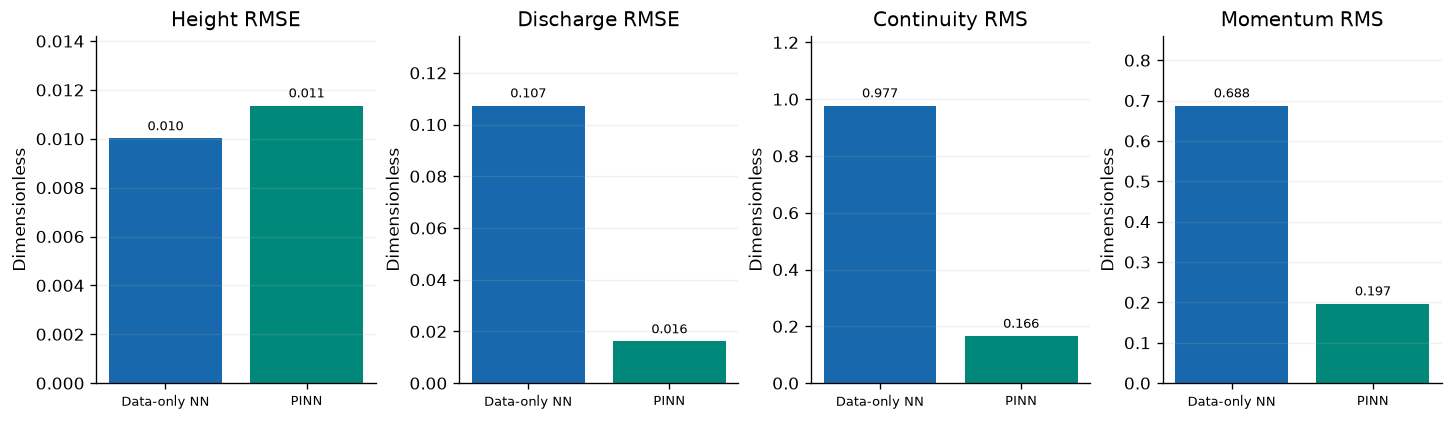

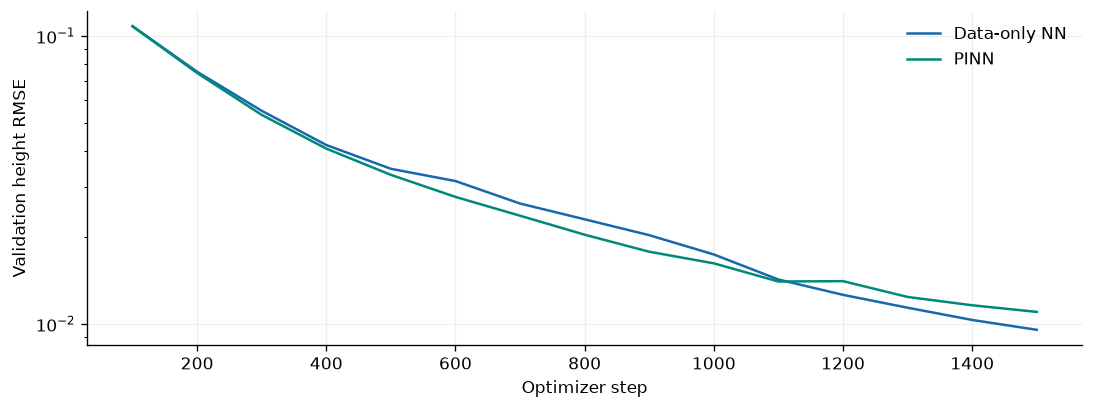

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), layout="constrained")
for ax, metric in zip(axes, ["Height RMSE", "Discharge RMSE", "Continuity RMS", "Momentum RMS"]):
    bars = ax.bar(synthetic_results.Model, synthetic_results[metric],
                  color=[COLORS[name] for name in synthetic_results.Model])
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
    ax.set(title=metric, ylabel="Dimensionless", ylim=(0, synthetic_results[metric].max() * 1.25))
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="y")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.3), layout="constrained")
for name, history in synthetic_history.items():
    ax.plot(history.Step, history["Validation height RMSE"], label=name, c=COLORS[name])
ax.set(xlabel="Optimizer step", ylabel="Validation height RMSE", yscale="log")
ax.legend(frameon=False)
ax.grid()
plt.show()

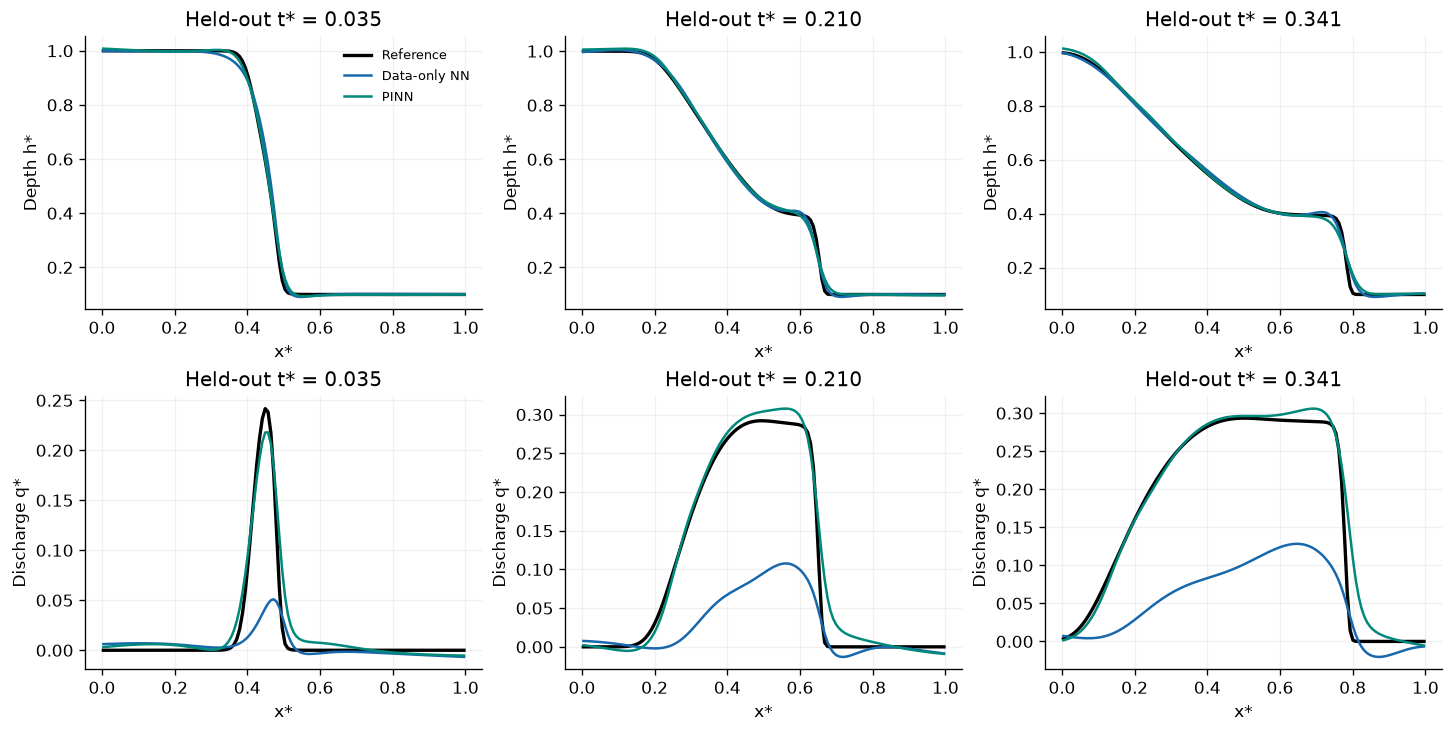

In [26]:
synthetic_predictions = {}
with torch.no_grad():
    query = xt_coordinates(sx, st[stest])
    for name, model in synthetic_models.items():
        synthetic_predictions[name] = model(query).numpy().reshape(len(stest), len(sx), 2)

fig, axes = plt.subplots(2, 3, figsize=(12, 6), layout="constrained")
for column, frame in enumerate([0, len(stest) // 2, len(stest) - 1]):
    for component, label in enumerate(["Depth h*", "Discharge q*"]):
        ax = axes[component, column]
        ax.plot(sx, state[stest[frame], :, component], c="black", lw=2, label="Reference")
        for name, prediction in synthetic_predictions.items():
            ax.plot(sx, prediction[frame, :, component], c=COLORS[name], label=name)
        ax.set(xlabel="x*", ylabel=label, title=f"Held-out t* = {st[stest[frame]]:.3f}")
        ax.grid()
axes[0, 0].legend(fontsize=8, frameon=False)
plt.show()

## 15. Save Models and Results

Save trained models, comparison tables, predictions, split indices, and run settings. These files make the results easy to inspect and reuse after the notebook finishes.

In [27]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
validation_results.to_csv(OUTPUT_DIR / "validation_results.csv", index=False)
test_results.to_csv(OUTPUT_DIR / "test_results.csv", index=False)
transfer_results.to_csv(OUTPUT_DIR / "wave3_transfer_results.csv", index=False)
synthetic_results.to_csv(OUTPUT_DIR / "synthetic_results.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "mlp_training_history.csv", index=False)

for name, model in regressors.items():
    joblib.dump(model, OUTPUT_DIR / f"{name.lower().replace(' ', '_')}.joblib")
torch.save({"state_dict": mlp.state_dict(), "feature_min": feature_scaler.data_min_.tolist(),
            "feature_max": feature_scaler.data_max_.tolist(), "target_mean": target_mean,
            "target_std": target_std, "selected_step": best_step}, OUTPUT_DIR / "mlp.pt")
for name, model in synthetic_models.items():
    torch.save(model.state_dict(), OUTPUT_DIR / f"{name.lower().replace(' ', '_')}.pt")

np.savez_compressed(OUTPUT_DIR / "test_predictions.npz", measured_wse_m=y_test,
                    **{name.lower().replace(' ', '_'): value for name, value in test_predictions.items()})
np.savez_compressed(OUTPUT_DIR / "split.npz", train_frames=train_frames, val_frames=val_frames,
                    test_frames=test_frames, sensor_ids=sensor_ids, heldout_ids=heldout_ids)
(OUTPUT_DIR / "run_config.json").write_text(json.dumps({
    "seed": SEED, "data_source": DATA_SOURCE, "sensors": N_SENSORS,
    "mlp_steps": MLP_STEPS, "pinn_steps": PINN_STEPS, "physics_weight": PHYSICS_WEIGHT,
    "selected_measured_model": selected_model,
    "measured_target": "WSE relative to initial bed (m)",
    "synthetic_data": "Numerical wet-bed release; dimensionless; no Nepal observations",
    "evaluation": "Within-wave spatial/time holdouts and frozen same-geometry wave transfer",
}, indent=2))
pd.DataFrame({"Saved file": [p.name for p in sorted(OUTPUT_DIR.iterdir()) if p.is_file()]})

,Saved file
0,data-only_nn.pt
1,mlp.pt
2,mlp_training_history.csv
3,pinn.pt
4,polynomial_ridge.joblib
5,random_forest.joblib
6,run_config.json
7,split.npz
8,synthetic_results.csv
9,test_predictions.npz


## Conclusion

In the saved run:

- **Measured reconstruction:** interpolation had the lowest validation RMSE and achieved a test RMSE of **3.44 mm**, followed by Random Forest at **3.81 mm** and the MLP at **4.73 mm**.
- **Transfer to wave 3:** errors increased for every model. The MLP had the lowest transfer RMSE at **6.72 mm**, showing that the best within-wave model did not lead the second-wave comparison.
- **Physics-informed learning:** the PINN reduced dimensionless discharge RMSE from **0.1073** to **0.0161** and lowered both physics residuals. Its depth RMSE was slightly higher than the data-only network's, so the improvement depended on the quantity evaluated.

These results support further study of flood reconstruction from sparse observations. For me, the next step is to test these ideas with Himalayan terrain and event observations, building toward research relevant to Nepal. The current laboratory and simulation benchmarks do not establish performance on a Nepal flood.